# 01 — Data Exploration (UNSW-NB15)

**Project:** Network Traffic Clustering and Novelty Detection
**Reference:** *Project Proposal V2*, Phase 2 (data loading and exploratory data analysis).

**Purpose of this notebook.** Understand and validate the raw dataset *before* any
feature engineering. It answers five questions:

1. Do the official files match their documented shape and schema?
2. How are identifiers, reference labels and features separated?
3. Which features are numerical, which are categorical, and what are their shapes?
4. Are there missing values, duplicates, infinities or invalid values?
5. What do the distributions, cardinalities and correlations tell us about the
   feature representation required in notebook 02?

This notebook is **descriptive only**. It does not encode, scale, split or model
anything, and the reference labels (`label`, `attack_cat`) are treated strictly as
*reference information* — they are never used as inputs.

## 0. Environment setup

In [1]:
# --- Environment setup -------------------------------------------------------
# Locate the project root so the notebook runs from anywhere (e.g. notebooks/)
# without depending on variables created by other notebooks.
import sys
from pathlib import Path

def _find_project_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Run this notebook inside the project repository.")

PROJECT_ROOT = _find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config.config import (
    RAW_DIR, FIGURES_DIR, METRICS_DIR, REPORTS_DIR, PROCESSED_DIR,
    TRAIN_FILE, TEST_FILE, FEATURE_DICT_FILE,
    EXPECTED_TRAIN_SHAPE, EXPECTED_TEST_SHAPE,
    RANDOM_SEED, ID_COLUMNS, LABEL_COLUMN, ATTACK_CAT_COLUMN,
    NUMERIC_FEATURES, CATEGORICAL_FEATURES,
)
from src.data.preprocess import (
    load_official_datasets, load_feature_dictionary,
    split_features_labels, identify_feature_types,
)

RANDOM_STATE = RANDOM_SEED
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
%matplotlib inline

for _d in (FIGURES_DIR, METRICS_DIR, REPORTS_DIR, PROCESSED_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

Project root: /home/aminelby/Network-Traffic-Clustering


## 1. Dataset inventory and loading

**Purpose.** Record exactly which files exist on disk (so the analysis is
reproducible) and load the two official splits. The dataset also ships as four
large partitioned raw files and a feature-description file; only the *official*
train/test CSVs are used for modelling, because they are already deduplicated and
label-annotated by the dataset authors.

In [2]:
inventory = []
for path in sorted(RAW_DIR.glob("*")):
    inventory.append({
        "file": path.name,
        "size_MB": round(path.stat().st_size / 1024**2, 2),
    })
inventory = pd.DataFrame(inventory)
display(inventory)

train_df, test_df = load_official_datasets()
print("Training set :", train_df.shape)
print("Testing set  :", test_df.shape)
print("Expected     :", EXPECTED_TRAIN_SHAPE, "and", EXPECTED_TEST_SHAPE)
assert train_df.shape == EXPECTED_TRAIN_SHAPE, "Training shape mismatch!"
assert test_df.shape == EXPECTED_TEST_SHAPE, "Testing shape mismatch!"
print("\n[OK] Both official splits match the documented dimensions.")

,file,size_MB
0,NUSW-NB15_features.csv,0.00
1,UNSW-NB15_1.csv,161.15
2,UNSW-NB15_2.csv,157.57
3,UNSW-NB15_3.csv,147.43
4,UNSW-NB15_4.csv,93.07
5,UNSW-NB15_LIST_EVENTS.csv,0.00
6,UNSW_NB15_testing-set.csv,30.80
7,UNSW_NB15_training-set.csv,14.67


Training set : (82332, 45)
Testing set  : (175341, 45)
Expected     : (82332, 45) and (175341, 45)

[OK] Both official splits match the documented dimensions.


The training and testing files match the expected **82,332 × 45** and
**175,341 × 45** shapes. The four partitioned `UNSW-NB15_1..4.csv` files (162–94 MB,
no header) are the pre-split originals; they are **not** used here because the
official splits are already the deduplicated, label-annotated benchmark the
proposal refers to. The raw directory is treated as read-only throughout.

## 2. Structure, column names and data types

**Purpose.** Confirm the schema: 45 columns, their dtypes, and how many columns
fall in each dtype family. This is the first place a schema surprise would appear.

In [3]:
print("Columns (%d):" % train_df.shape[1])
print(list(train_df.columns))

dtype_counts = train_df.dtypes.astype(str).value_counts()
display(dtype_counts.rename("count").to_frame())

schema = pd.DataFrame({
    "column": train_df.columns,
    "dtype_train": train_df.dtypes.astype(str).values,
    "dtype_test": test_df.dtypes.astype(str).values,
})
schema["dtype_match"] = schema["dtype_train"] == schema["dtype_test"]
print("\nTrain/test dtype mismatches:", int((~schema["dtype_match"]).sum()))
display(schema)

Columns (45):
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


,count
int64,30
float64,11
str,4



Train/test dtype mismatches: 0


,column,dtype_train,dtype_test,dtype_match
0,id,int64,int64,True
1,dur,float64,float64,True
2,proto,str,str,True
3,service,str,str,True
4,state,str,str,True
5,spkts,int64,int64,True
6,dpkts,int64,int64,True
7,sbytes,int64,int64,True
8,dbytes,int64,int64,True
9,rate,float64,float64,True


The schema is clean: 30 integer, 11 float and 4 string columns, and the train and
test dtypes agree column-for-column. The four string columns are the three
categorical features (`proto`, `service`, `state`) plus the reference label
`attack_cat`.

## 3. Feature dictionary inspection

**Purpose.** Cross-check the column names against the official feature
description file (`NUSW-NB15_features.csv` — note the deliberate filename). This
tells us the intended type and meaning of each column and justifies later
decisions (which columns are identifiers, which are timing/rate features, etc.).

In [4]:
feature_dict = load_feature_dictionary()
print("Feature dictionary shape:", feature_dict.shape)
display(feature_dict)

dict_names = set(feature_dict["Name"].str.strip())
csv_names = set(train_df.columns)
# The dictionary is written for the *raw* partitioned files (49 columns, incl.
# srcip/dstip/sport/dsport). The official train/test CSVs use a reduced,
# lower-cased 45-column schema.
print("Dictionary entries :", len(dict_names))
print("CSV columns        :", len(csv_names))
print("\nIn dictionary but not in CSV (expected: raw-only identifiers):")
print(sorted(n for n in dict_names if n.lower() not in {c.lower() for c in csv_names}))

Feature dictionary shape: (49, 4)


,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol
5,6,state,nominal,Indicates to the state and its dependent proto...
6,7,dur,Float,Record total duration
7,8,sbytes,Integer,Source to destination transaction bytes
8,9,dbytes,Integer,Destination to source transaction bytes
9,10,sttl,Integer,Source to destination time to live value


Dictionary entries : 49
CSV columns        : 45

In dictionary but not in CSV (expected: raw-only identifiers):
['Dintpkt', 'Ltime', 'Sintpkt', 'Stime', 'ct_src_ ltm', 'dmeansz', 'dsport', 'dstip', 'res_bdy_len', 'smeansz', 'sport', 'srcip']


The dictionary documents the **49-column raw schema** (including `srcip`, `sport`,
`dstip`, `dsport`). The official train/test CSVs use a reduced **45-column**
schema in which the IP addresses and ports are **already absent**, and the
feature names are lower-cased (dictionary `Sload`/`Dload`/`Spkts` → CSV
`sload`/`dload`/`spkts`).

**Consequence:** the proposal's rule "exclude IP addresses" is satisfied *by
construction* in the official splits — there is nothing to drop. The only
identifier column present is `id`, which we drop explicitly below. This is
documented rather than assumed.

## 4. Separating identifiers, reference labels and features

**Purpose.** Fix the column roles once, according to Proposal V2 §6. Identifiers
and labels must never enter a feature matrix.

In [5]:
# Identifier: `id` is a row counter that restarts at 1 in each file, so it is NOT
# unique across the two splits -> it carries no traffic information and is dropped.
print("id range train:", (int(train_df['id'].min()), int(train_df['id'].max())),
      "| id range test:", (int(test_df['id'].min()), int(test_df['id'].max())))
print("id unique in train:", train_df['id'].is_unique,
      "| id unique in test:", test_df['id'].is_unique)

# Roles
identifier_cols = list(ID_COLUMNS)
label_cols = [ATTACK_CAT_COLUMN, LABEL_COLUMN]
feature_cols = [c for c in train_df.columns if c not in identifier_cols + label_cols]

print("\nIdentifier columns :", identifier_cols)
print("Reference labels   :", label_cols)
print("Feature columns    :", len(feature_cols))

# Build the separated views (labels kept aligned by index).
X_train_raw, y_train = split_features_labels(train_df)
X_test_raw, y_test = split_features_labels(test_df)
print("\nX_train_raw:", X_train_raw.shape, "| y_train:", y_train.shape)
print("X_test_raw :", X_test_raw.shape, "| y_test :", y_test.shape)

assert not set(label_cols) & set(X_train_raw.columns)
assert "id" not in X_train_raw.columns

id range train: (1, 82332) | id range test: (1, 175341)
id unique in train: True | id unique in test: True

Identifier columns : ['id']
Reference labels   : ['attack_cat', 'label']
Feature columns    : 42

X_train_raw: (82332, 42) | y_train: (82332, 2)
X_test_raw : (175341, 42) | y_test : (175341, 2)


Roles are now fixed:

* **Identifier (dropped):** `id`.
* **Reference labels (kept separate, never modelled):** `label` (binary target) and
  `attack_cat` (10-way attack category).
* **Features:** the remaining **42** columns handed to the representation stage.

Both label columns are preserved in dedicated frames so downstream phases can
audit results, but they are excluded from `X`.

## 5. Numerical and categorical feature identification

**Purpose.** Split the 42 features into a numerical block and a categorical block,
and cross-check against the declared groups in `config.py` (which must always
agree with what the data actually shows).

In [6]:
numeric_features, categorical_features = identify_feature_types(X_train_raw)
print("Numerical features  (%2d): %s" % (len(numeric_features), numeric_features))
print("\nCategorical features (%2d): %s" % (len(categorical_features), categorical_features))

assert numeric_features == NUMERIC_FEATURES, "Numeric feature set differs from config!"
assert categorical_features == CATEGORICAL_FEATURES, "Categorical feature set differs from config!"
print("\n[OK] Data-derived feature groups match the declared config groups.")

Numerical features  (39): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']

Categorical features ( 3): ['proto', 'service', 'state']

[OK] Data-derived feature groups match the declared config groups.


## 6. Data-quality checks

**Purpose.** Before trusting any statistic, check for missing values, duplicated
rows, infinities (common in derived rate features) and invalid negatives. Also
flag constant columns, which cannot help any distance-based method.

In [7]:
def quality_report(df, name):
    num = df.select_dtypes(include=[np.number])
    rep = {
        "rows": len(df),
        "columns": df.shape[1],
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "infinite_values": int(np.isinf(num.to_numpy()).sum()),
        "n_constant_columns": int((df.nunique(dropna=False) <= 1).sum()),
        "negative_numeric_values": int((num.to_numpy() < 0).sum()),
    }
    return pd.Series(rep, name=name)

checks = pd.concat([quality_report(train_df, "train"), quality_report(test_df, "test")], axis=1)
display(checks)

# Column-level missing / negative detail (only non-empty rows shown).
miss = pd.DataFrame({"train_missing": train_df.isna().sum(), "test_missing": test_df.isna().sum()})
display(miss[miss.sum(axis=1) > 0] if miss.sum(axis=1).sum() else "No missing values anywhere.")

,train,test
rows,82332,175341
columns,45,45
missing_values,0,0
duplicate_rows,0,0
infinite_values,0,0
n_constant_columns,0,0
negative_numeric_values,0,0


'No missing values anywhere.'

In [8]:
# Negative values: which columns, if any?
num_train = train_df.select_dtypes(include=[np.number])
neg = {c: int((num_train[c] < 0).sum()) for c in num_train.columns if (num_train[c] < 0).any()}
print("Columns with negative values:", neg if neg else "none")

# Columns with fewer than 3 distinct values (near-constant / flag columns)
low_card = {c: int(train_df[c].nunique()) for c in feature_cols if train_df[c].nunique() <= 3}
print("\nLow-cardinality feature columns (<=3 distinct values):")
for c, n in sorted(low_card.items(), key=lambda kv: kv[1]):
    print(f"  {c:18s} {n} distinct")

Columns with negative values: none

Low-cardinality feature columns (<=3 distinct values):
  is_sm_ips_ports    2 distinct
  is_ftp_login       3 distinct
  ct_ftp_cmd         3 distinct


**Quality verdict — the dataset is unusually clean:**

| Check | Training | Testing |
|---|---|---|
| Missing values | 0 | 0 |
| Duplicate rows | 0 | 0 |
| Infinite values | 0 | 0 |
| Negative numeric values | 0 | 0 |
| Constant columns | 0 | 0 |

So **no imputation is required**, no infinity clipping is required, and no
de-duplication is required. This removes a whole class of preprocessing decisions
— but we still verify it explicitly, as the proposal demands, rather than assume it.

Two columns deserve a note because they *look* binary but are not: `is_ftp_login`
and `ct_ftp_cmd` take values {0, 1, 2}, and `is_sm_ips_ports` is a true binary
{0, 1} flag. These are treated specially in notebook 02.

## 7. Numerical descriptive statistics

**Purpose.** Characterise each numerical feature: central tendency, spread, tail
weight (skewness) and the fraction of exact zeros. Skewness is the statistic that
drives the log-transform decision in notebook 02.

In [9]:
numeric_summary = X_train_raw[numeric_features].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).T
numeric_summary["skewness"] = X_train_raw[numeric_features].skew()
numeric_summary["zero_fraction"] = (X_train_raw[numeric_features] == 0).mean()
numeric_summary["n_unique"] = X_train_raw[numeric_features].nunique()
numeric_summary["abs_skewness"] = numeric_summary["skewness"].abs()
numeric_summary = numeric_summary.sort_values("abs_skewness", ascending=False)

cols = ["mean", "std", "min", "25%", "50%", "75%", "95%", "99%", "max",
        "skewness", "zero_fraction", "n_unique"]
display(numeric_summary[cols].round(4))

numeric_summary[cols].round(6).to_csv(METRICS_DIR / "01_numerical_summary.csv")
print("Saved ->", METRICS_DIR / "01_numerical_summary.csv")

,mean,std,min,25%,50%,75%,95%,99%,max,skewness,zero_fraction,n_unique
trans_depth,9.430000e-02,5.429000e-01,0.0,0.0000,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.310000e+02,170.7944,0.9079,8
response_body_len,1.595372e+03,3.806697e+04,0.0,0.0000,0.000000e+00,0.000000e+00,1.504500e+02,3.924000e+03,5.242880e+06,74.6352,0.9313,1190
djit,5.351804e+02,3.635305e+03,0.0,0.0000,0.000000e+00,1.284599e+02,2.218934e+03,9.049685e+03,4.631992e+05,60.5623,0.5047,38381
dloss,6.308600e+00,5.570800e+01,0.0,0.0000,0.000000e+00,2.000000e+00,1.800000e+01,9.769000e+01,5.507000e+03,54.4656,0.5005,311
sbytes,7.993908e+03,1.716423e+05,24.0,114.0000,5.340000e+02,1.280000e+03,1.247200e+04,6.997004e+04,1.435577e+07,53.7785,0.0000,4489
dbytes,1.323379e+04,1.514715e+05,0.0,0.0000,1.780000e+02,9.560000e+02,3.062200e+04,2.077510e+05,1.465753e+07,52.5504,0.4373,4034
sloss,4.753700e+00,6.464960e+01,0.0,0.0000,1.000000e+00,3.000000e+00,1.100000e+01,3.900000e+01,5.319000e+03,52.4653,0.4776,253
dpkts,1.754590e+01,1.155741e+02,0.0,0.0000,2.000000e+00,1.000000e+01,5.400000e+01,2.520000e+02,1.101800e+04,49.3041,0.4373,436
spkts,1.866650e+01,1.339164e+02,1.0,2.0000,6.000000e+00,1.200000e+01,6.000000e+01,2.080000e+02,1.064600e+04,47.7478,0.0000,420
dinpkt,1.217013e+02,1.292379e+03,0.0,0.0000,1.000000e-02,6.313640e+01,1.676269e+02,5.560524e+02,5.773924e+04,23.0130,0.4374,37617


Saved -> /home/aminelby/Network-Traffic-Clustering/results/metrics/01_numerical_summary.csv


The picture is the textbook one for network flow data:

* **Extreme right skew** in bytes/packets/durations/jitters — skewness well above
  10, up to ~170 for `trans_depth` and ~75 for `response_body_len`. Minimum values
  are ≥ 0, i.e. these are non-negative heavy-tailed magnitudes.
* **High zero fractions** in the destination/setup columns (`dbytes`, `dloss`,
  `djit`, `tcprtt`, `synack`, `ackdat` ≈ 44–50% zeros) and near-total zeros in the
  sparse flags (`is_ftp_login`, `ct_ftp_cmd` ≈ 99%, `trans_depth` ≈ 91%,
  `response_body_len` ≈ 93%). These are *not* heavy tails to be logged blindly —
  they are sparsity, and they need different handling.
* **Bounded, low-cardinality** columns (`sttl`, `dttl`, `swin`, `dwin`, with 8–14
  distinct values) have near-zero or negative skew — no transformation warranted.
* `stcpb` / `dtcpb` (TCP base sequence numbers) have ~40k distinct values and skew
  near 1: essentially large pseudo-identifiers with no meaningful magnitude.

This split of "heavy-tail vs sparse vs bounded" is exactly what notebook 02 uses
to decide *which* features get `log1p` and which do not.

## 8. Categorical feature distributions

**Purpose.** Quantify cardinality and frequency skew for `proto`, `service`,
`state` (and, for reference only, `attack_cat`). High cardinality is the central
problem for Euclidean-distance clustering, so we measure it precisely here.

In [10]:
cat_cols_to_profile = categorical_features + [ATTACK_CAT_COLUMN]
rows = []
for col in cat_cols_to_profile:
    vc = train_df[col].value_counts()
    share = train_df[col].value_counts(normalize=True)
    rows.append({
        "column": col,
        "n_categories_train": train_df[col].nunique(),
        "n_categories_test": test_df[col].nunique(),
        "top_category": vc.index[0],
        "top_share": round(float(share.iloc[0]), 4),
        "top3_share": round(float(share.head(3).sum()), 4),
        "rarest_share": round(float(share.iloc[-1]), 6),
        "n_categories_lt_1pct": int((share < 0.01).sum()),
    })
categorical_summary = pd.DataFrame(rows)
display(categorical_summary)

categorical_summary.to_csv(METRICS_DIR / "01_categorical_summary.csv", index=False)
print("Saved ->", METRICS_DIR / "01_categorical_summary.csv")

,column,n_categories_train,n_categories_test,top_category,top_share,top3_share,rarest_share,n_categories_lt_1pct
0,proto,131,133,tcp,0.5234,0.9234,0.000364,127
1,service,13,13,-,0.5727,0.9329,0.000061,7
2,state,7,9,FIN,0.4778,0.9776,0.000012,3
3,attack_cat,10,10,Normal,0.4494,0.8138,0.000534,4


Saved -> /home/aminelby/Network-Traffic-Clustering/results/metrics/01_categorical_summary.csv


In [11]:
# Full frequency tables for the three features (top 15 + coverage).
for col in categorical_features:
    vc = train_df[col].value_counts()
    share = train_df[col].value_counts(normalize=True)
    cov = share.cumsum()
    tbl = pd.DataFrame({"count": vc, "share": share.round(5), "cum_share": cov.round(5)}).head(15)
    print(f"\n===== {col} (cardinality train={vc.shape[0]}, "
          f"test={test_df[col].nunique()}) =====")
    display(tbl)

# Coverage of the top-10 proto categories (the crux of the encoding problem).
for k in (3, 5, 10, 20, 30):
    cov = train_df["proto"].value_counts(normalize=True).head(k).sum()
    print(f"proto top-{k:>2}: cumulative coverage = {cov:.4f}")

# Unseen categories in the test split (a real leakage/trickiness check).
for col in categorical_features:
    unseen = set(test_df[col].unique()) - set(train_df[col].unique())
    print(f"\n{col}: {len(unseen)} test categories unseen in train -> {sorted(unseen)}")


===== proto (cardinality train=131, test=133) =====


,count,share,cum_share
proto,,,
tcp,43095,0.52343,0.52343
udp,29418,0.35731,0.88074
unas,3515,0.04269,0.92343
arp,987,0.01199,0.93542
ospf,676,0.00821,0.94363
sctp,324,0.00394,0.94757
any,96,0.00117,0.94873
gre,88,0.00107,0.94980
rsvp,64,0.00078,0.95058



===== service (cardinality train=13, test=13) =====


,count,share,cum_share
service,,,
-,47153,0.57272,0.57272
dns,21367,0.25952,0.83224
http,8287,0.10065,0.93289
smtp,1851,0.02248,0.95538
ftp,1552,0.01885,0.97423
ftp-data,1396,0.01696,0.99118
pop3,423,0.00514,0.99632
ssh,204,0.00248,0.99880
ssl,30,0.00036,0.99916



===== state (cardinality train=7, test=9) =====


,count,share,cum_share
state,,,
FIN,39339,0.47781,0.47781
INT,34163,0.41494,0.89275
CON,6982,0.08480,0.97755
REQ,1842,0.02237,0.99993
ACC,4,0.00005,0.99998
RST,1,0.00001,0.99999
CLO,1,0.00001,1.00000


proto top- 3: cumulative coverage = 0.9234
proto top- 5: cumulative coverage = 0.9436
proto top-10: cumulative coverage = 0.9513
proto top-20: cumulative coverage = 0.9566
proto top-30: cumulative coverage = 0.9606

proto: 2 test categories unseen in train -> ['icmp', 'rtp']

service: 0 test categories unseen in train -> []

state: 4 test categories unseen in train -> ['ECO', 'PAR', 'URN', 'no']


**Key findings.**

* **`proto` — very high cardinality: 131 categories in train, 133 in test.** The
  top 2 (`tcp`, `udp`) already cover ~88%; the top 10 cover **95.1%**; the
  remaining **121 categories share only 4.9%**, many appearing a handful of times.
  Two test categories (`ipv6-opts`-style rare values) never appear in training.
* **`service` — moderate cardinality: 13 categories.** The `-` token (no specific
  service) dominates at 57%, and the top 6 cover **99.1%**.
* **`state` — low cardinality: 7 in train, 9 in test.** `FIN` and `INT` dominate.
  Two unseen test categories appear.
* **`attack_cat`** has 10 categories (9 attacks + `Normal`) and is strongly
  imbalanced — this matters for the *evaluation design* of Chapter B, not for
  anything we compute now.

The unseen categories matter: a full one-hot encoder fit on training data will
**silently produce all-zero rows** for those test categories. Any representation
choice must make this behaviour explicit (notebook 02).

## 9. Reference-label distributions (descriptive understanding only)

**Purpose.** Quantify the attack rate and the per-category sizes. Per the
label-policy (§6), labels are inspected here only to *understand* the data and to
size the Chapter-B evaluation design. They are never used as inputs, and never to
make preprocessing decisions.

In [12]:
label_frames = []
for name, df in [("train", train_df), ("test", test_df)]:
    vc = df[LABEL_COLUMN].value_counts().sort_index()
    label_frames.append(pd.Series({
        "rows": len(df),
        "normal (label=0)": int(vc.get(0, 0)),
        "attack (label=1)": int(vc.get(1, 0)),
        "attack_rate": round(float(df[LABEL_COLUMN].mean()), 4),
    }, name=name))
label_summary = pd.concat(label_frames, axis=1)
display(label_summary)

attack_cat_train = train_df[ATTACK_CAT_COLUMN].value_counts().to_frame("count_train")
attack_cat_train["share_train"] = (attack_cat_train["count_train"] / len(train_df)).round(5)
attack_cat_test = test_df[ATTACK_CAT_COLUMN].value_counts().to_frame("count_test")
attack_cat_table = attack_cat_train.join(attack_cat_test)
display(attack_cat_table)

label_summary.to_csv(METRICS_DIR / "01_label_summary.csv")
attack_cat_table.to_csv(METRICS_DIR / "01_attack_cat_summary.csv")
print("Saved label + attack_cat summaries ->", METRICS_DIR)

,train,test
rows,82332.0000,175341.0000
normal (label=0),37000.0000,56000.0000
attack (label=1),45332.0000,119341.0000
attack_rate,0.5506,0.6806


,count_train,share_train,count_test
attack_cat,,,
Normal,37000,0.44940,56000
Generic,18871,0.22921,40000
Exploits,11132,0.13521,33393
Fuzzers,6062,0.07363,18184
DoS,4089,0.04966,12264
Reconnaissance,3496,0.04246,10491
Analysis,677,0.00822,2000
Backdoor,583,0.00708,1746
Shellcode,378,0.00459,1133


Saved label + attack_cat summaries -> /home/aminelby/Network-Traffic-Clustering/results/metrics


**Reading.** The training split is ~55% attack, the testing split ~68% attack —
the benchmark is *not* balanced, and the attack rate differs between splits
(another reason every split must be seeded and documented). Attack categories are
strongly imbalanced: `Generic` (18,871) and `Exploits` (11,132) dominate, while
`Worms` (44) and `Shellcode` (378) are rare. In Chapter B, **37,000** normal
training flows are available to build the model of normal.

These numbers are recorded now because they determine how Chapter B will be
evaluated later (per-category recall, flagging budgets). No preprocessing
decision is taken from them.

## 10. Feature-distribution visualisations

**Purpose.** Make the heavy tails, sparsity and categorical skew visible. Figures
are written to `results/figures/` for reuse in the report.

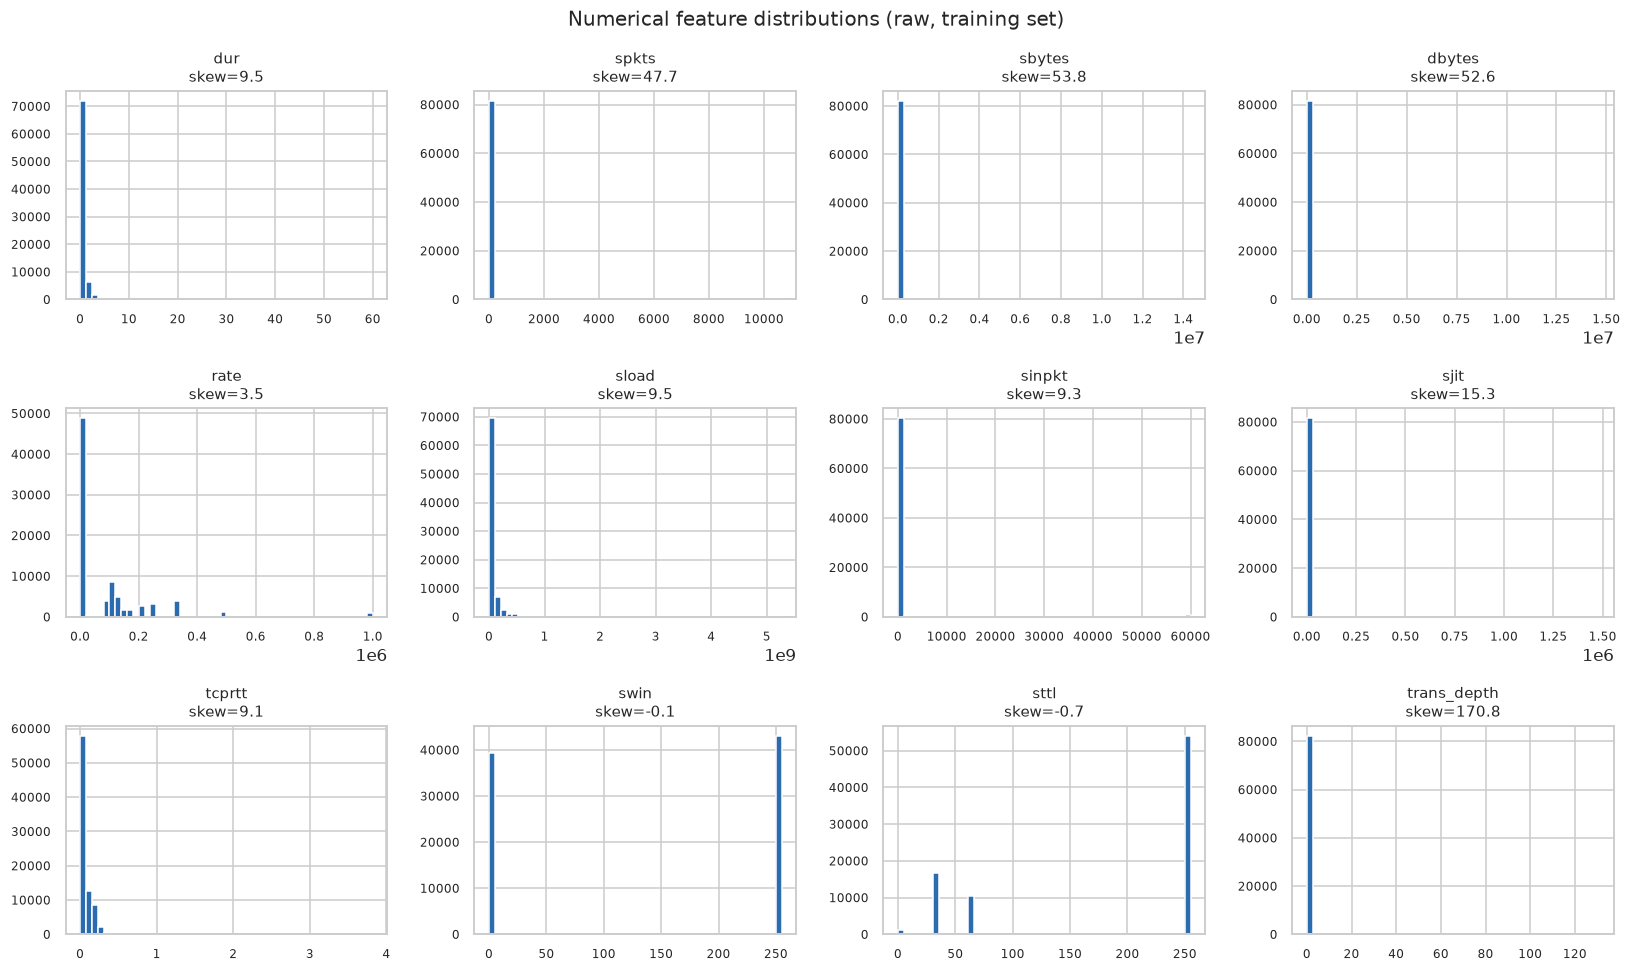

Saved -> /home/aminelby/Network-Traffic-Clustering/results/figures/01_numerical_distributions.png


In [13]:
# 10a. Representative numerical distributions (raw scale) ----------------------
example_features = [
    "dur", "spkts", "sbytes", "dbytes", "rate", "sload",
    "sinpkt", "sjit", "tcprtt", "swin", "sttl", "trans_depth",
]
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.ravel(), example_features):
    ax.hist(X_train_raw[col], bins=50, color="#2b6cb0")
    ax.set_title(f"{col}\nskew={X_train_raw[col].skew():.1f}", fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle("Numerical feature distributions (raw, training set)", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_numerical_distributions.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved ->", FIGURES_DIR / "01_numerical_distributions.png")

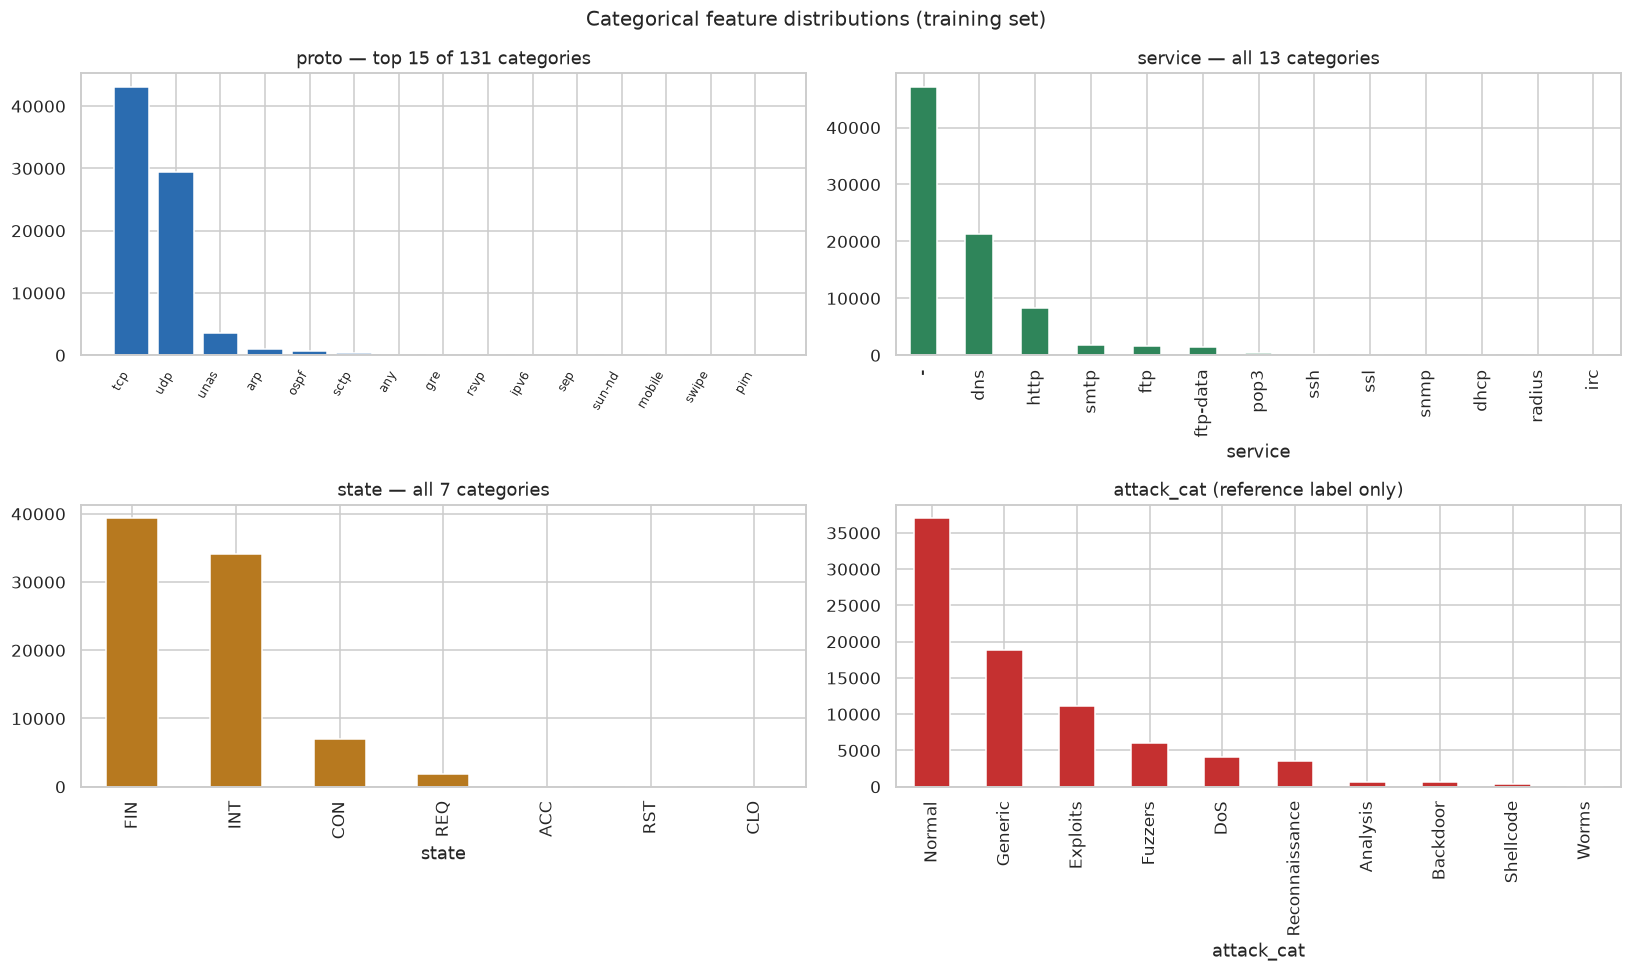

Saved -> /home/aminelby/Network-Traffic-Clustering/results/figures/01_categorical_distributions.png


In [14]:
# 10b. Categorical distributions ----------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

top_proto = train_df["proto"].value_counts().head(15)
axes[0, 0].bar(range(len(top_proto)), top_proto.values, color="#2b6cb0")
axes[0, 0].set_xticks(range(len(top_proto)))
axes[0, 0].set_xticklabels(top_proto.index, rotation=60, ha="right", fontsize=8)
axes[0, 0].set_title(f"proto — top 15 of {train_df['proto'].nunique()} categories")

train_df["service"].value_counts().plot.bar(ax=axes[0, 1], color="#2f855a")
axes[0, 1].set_title(f"service — all {train_df['service'].nunique()} categories")

train_df["state"].value_counts().plot.bar(ax=axes[1, 0], color="#b7791f")
axes[1, 0].set_title(f"state — all {train_df['state'].nunique()} categories")

train_df[ATTACK_CAT_COLUMN].value_counts().plot.bar(ax=axes[1, 1], color="#c53030")
axes[1, 1].set_title("attack_cat (reference label only)")

fig.suptitle("Categorical feature distributions (training set)", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_categorical_distributions.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved ->", FIGURES_DIR / "01_categorical_distributions.png")

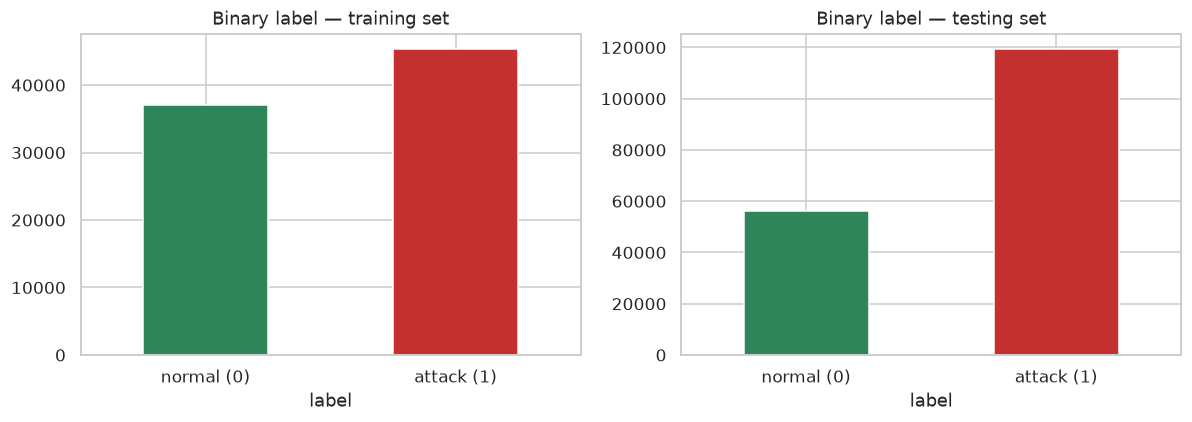

Saved -> /home/aminelby/Network-Traffic-Clustering/results/figures/01_label_distribution.png


In [15]:
# 10c. Label balance ----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_df[LABEL_COLUMN].value_counts().sort_index().plot.bar(
    ax=axes[0], color=["#2f855a", "#c53030"])
axes[0].set_xticklabels(["normal (0)", "attack (1)"], rotation=0)
axes[0].set_title("Binary label — training set")
test_df[LABEL_COLUMN].value_counts().sort_index().plot.bar(
    ax=axes[1], color=["#2f855a", "#c53030"])
axes[1].set_xticklabels(["normal (0)", "attack (1)"], rotation=0)
axes[1].set_title("Binary label — testing set")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_label_distribution.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved ->", FIGURES_DIR / "01_label_distribution.png")

## 11. Correlation analysis and redundancy

**Purpose.** Identify strongly related feature pairs. Highly correlated features
double-count the same signal in a Euclidean distance, so this informs the feature
selection discussion in notebook 02. We use Pearson correlation on the raw
numerical block (correlation is monotone-invariant, so log1p does not change
Spearman-style near-duplicates materially).

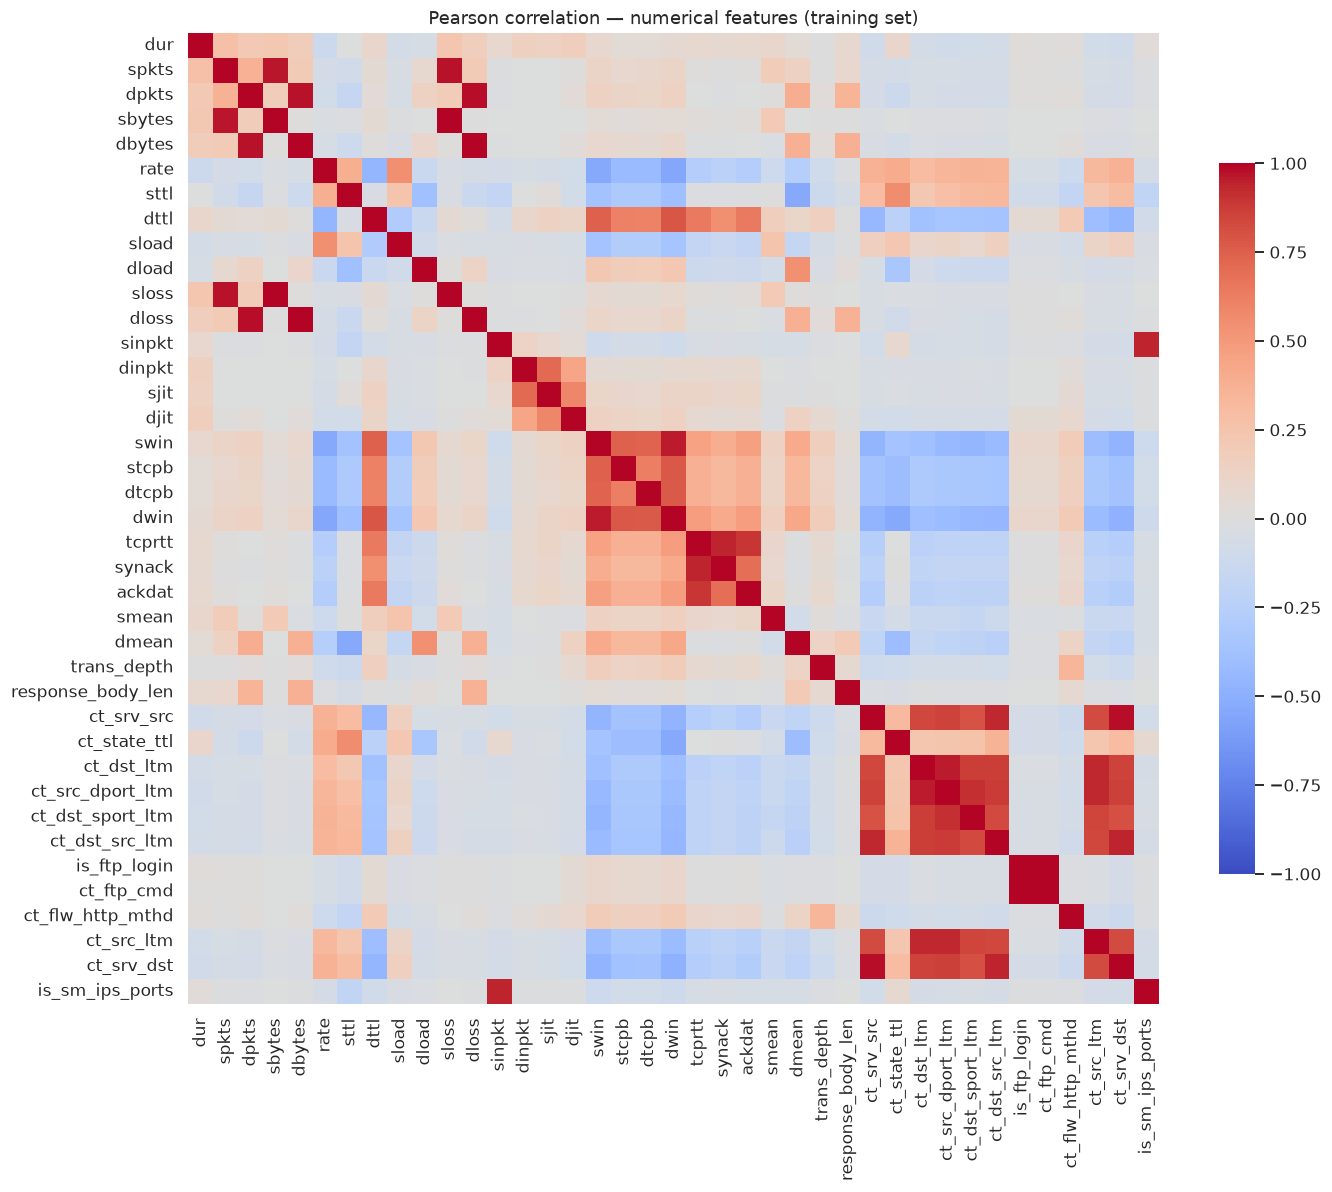

Saved -> /home/aminelby/Network-Traffic-Clustering/results/figures/01_correlation_heatmap.png


In [16]:
corr = X_train_raw[numeric_features].corr()

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Pearson correlation — numerical features (training set)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_correlation_heatmap.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved ->", FIGURES_DIR / "01_correlation_heatmap.png")

In [17]:
# Strongly correlated pairs (|r| > 0.9)
corr_abs = corr.abs().to_numpy(copy=True)
np.fill_diagonal(corr_abs, 0.0)
pairs = [
    {"feature_a": numeric_features[i], "feature_b": numeric_features[j],
     "abs_corr": round(float(corr_abs[i, j]), 4)}
    for i in range(len(numeric_features))
    for j in range(i + 1, len(numeric_features))
    if corr_abs[i, j] > 0.9
]
correlation_pairs = pd.DataFrame(pairs).sort_values("abs_corr", ascending=False)
display(correlation_pairs)

# Exact duplicate columns? (|r| == 1)
exact = correlation_pairs[correlation_pairs["abs_corr"] >= 0.9999]
print("Exactly duplicated numerical columns:", len(exact))

correlation_pairs.to_csv(METRICS_DIR / "01_correlation_pairs.csv", index=False)
print("Saved ->", METRICS_DIR / "01_correlation_pairs.csv")

,feature_a,feature_b,abs_corr
5,dbytes,dloss,0.9971
4,sbytes,sloss,0.9950
16,is_ftp_login,ct_ftp_cmd,0.9943
3,dpkts,dloss,0.9815
10,ct_srv_src,ct_srv_dst,0.9778
2,dpkts,dbytes,0.9764
1,spkts,sloss,0.9736
0,spkts,sbytes,0.9657
11,ct_dst_ltm,ct_src_dport_ltm,0.9604
7,swin,dwin,0.9601


Exactly duplicated numerical columns: 0
Saved -> /home/aminelby/Network-Traffic-Clustering/results/metrics/01_correlation_pairs.csv


**Redundancy findings.** There are **no perfectly duplicated columns** (no pair
reaches |r| = 1), so nothing is dropped on an exact-duplicate criterion. There are,
however, strong correlations that reflect *derived* quantities:

* `dbytes ↔ dloss` (0.997) and `sbytes ↔ sloss` (0.995) — byte counts and loss
  counts move together.
* `is_ftp_login ↔ ct_ftp_cmd` (0.994) — both near-empty FTP flags.
* `spkts ↔ sbytes` (0.966), `dpkts ↔ dbytes` (0.976) — packet/byte coupling.
* `ct_srv_src ↔ ct_srv_dst` (0.978) and a cluster of `ct_*` connection-count
  features correlating at 0.91–0.96 — they count overlapping flows.
* `tcprtt ↔ synack` (0.940) — setup time decomposition.

Because none is an exact duplicate, the conservative and reproducible choice is to
**keep all features** and document the redundancy as a limitation, rather than drop
columns by a subjective threshold. Removing near-duplicates would be a modelling
decision that changes every downstream distance, so it is left for the
representation discussion (notebook 02) where its effect can be measured.

## 12. Observations and conclusions

**Dataset integrity.** The official splits match their documented shapes exactly
(82,332 × 45 train, 175,341 × 45 test), with zero missing values, zero duplicate
rows, zero infinities and zero negatives. No cleaning is required — but every
check was run, not assumed.

**Schema and roles.** 45 columns = 1 identifier (`id`) + 39 numerical features +
3 categorical features (`proto`, `service`, `state`) + 2 reference labels
(`label`, `attack_cat`). IP addresses and ports are absent from the official
splits by construction, so the proposal's identifier-exclusion rule reduces to
dropping `id`. Roles are fixed in `config.py`.

**The two hard representation problems identified for notebook 02:**

1. **Heavy tails.** ~30 non-negative features have skewness > 1 (up to ~170).
   `log1p` is the natural candidate, but it must **not** be applied blindly: the
   sparse 0/1/2 flags and the bounded TTL/window columns do not benefit from it.
2. **Categorical cardinality.** `proto` has 131 training categories with the top
   10 covering 95.1%; a naive full one-hot would add ~131 largely-empty columns
   and inflate Euclidean distances. `service` (13) and `state` (7) are milder.
   Two test categories are unseen in training, so the encoder must degrade
   gracefully (an explicit "other" bucket or `handle_unknown="ignore"`).

**Labels.** Attack rate is 55% (train) / 68% (test); `attack_cat` is strongly
imbalanced. These facts are recorded for the Chapter-B evaluation design and were
**not** used to shape any preprocessing decision.

**Handoff.** Everything needed to design the feature representation is now on the
table: clean data, fixed column roles, quantified skewness, quantified
cardinality, and a correlation map. Notebook **02_feature_representation.ipynb**
turns these into explicit, measured representation decisions.

In [18]:
# Persist a compact EDA summary for the report folder.
summary_lines = [
    "# 01 - EDA key facts",
    "",
    f"- train shape: {train_df.shape}, test shape: {test_df.shape}",
    f"- identifier: {identifier_cols} (dropped)",
    f"- reference labels: {label_cols} (kept separate)",
    f"- numerical features: {len(numeric_features)}",
    f"- categorical features: {len(categorical_features)} -> {categorical_features}",
    f"- missing / duplicates / infinities / negatives: 0 in both splits",
    f"- proto cardinality: {train_df['proto'].nunique()} (train), top-10 coverage "
    f"{train_df['proto'].value_counts(normalize=True).head(10).sum():.4f}",
    f"- service cardinality: {train_df['service'].nunique()}, "
    f"state cardinality: {train_df['state'].nunique()}",
    f"- attack rate: train {train_df[LABEL_COLUMN].mean():.4f}, "
    f"test {test_df[LABEL_COLUMN].mean():.4f}",
    f"- normal flows in training set (Chapter B pool): {int((train_df[LABEL_COLUMN]==0).sum())}",
    "",
    "See results/metrics/01_*.csv for full tables and results/figures/01_*.png for plots.",
]
(REPORTS_DIR / "01_eda_key_facts.md").write_text("\n".join(summary_lines))
print("Saved ->", REPORTS_DIR / "01_eda_key_facts.md")
print("\n=== Notebook 01 complete: dataset validated, roles fixed, EDA recorded. ===")

Saved -> /home/aminelby/Network-Traffic-Clustering/results/reports/01_eda_key_facts.md

=== Notebook 01 complete: dataset validated, roles fixed, EDA recorded. ===
